In [34]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [35]:
df_sales_analysis = pd.read_csv('DataSetOfSalesAnalysis.csv')

In [36]:
df_sales_analysis.head()

,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500


<font size=5>Data Wrangling<font>

<font size= 4>1. Inspect the data for missing or incorrect data.<font>

In [37]:
missing_data = df_sales_analysis.isna().sum()
missing_data

Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64

In [38]:
incorrect_sales_data=df_sales_analysis[df_sales_analysis['Sales']<0]
incorrect_sales_data

,Date,Time,State,Group,Unit,Sales


In [39]:
incorrect_unit_data = df_sales_analysis[df_sales_analysis['Unit']<0]
incorrect_unit_data

,Date,Time,State,Group,Unit,Sales


<font size=3>We observed that there is no missing or incorrect data.<font>

<font size=4>2. Data Normalization<font>

In [40]:
df_sales_analysis['Sales_Normalized'] = (df_sales_analysis['Sales'] - df_sales_analysis['Sales'].min())/(df_sales_analysis['Sales'].max() - df_sales_analysis['Sales'].min())
df_sales_analysis['Unit_Normalized'] = (df_sales_analysis['Unit'] - df_sales_analysis['Unit'].min())/(df_sales_analysis['Unit'].max() - df_sales_analysis['Unit'].min())

In [41]:
df_sales_analysis

,Date,Time,State,Group,Unit,Sales,Sales_Normalized,Unit_Normalized
0,1-Oct-2020,Morning,WA,Kids,8,20000,0.095238,0.095238
1,1-Oct-2020,Morning,WA,Men,8,20000,0.095238,0.095238
2,1-Oct-2020,Morning,WA,Women,4,10000,0.031746,0.031746
3,1-Oct-2020,Morning,WA,Seniors,15,37500,0.206349,0.206349
4,1-Oct-2020,Afternoon,WA,Kids,3,7500,0.015873,0.015873
...,...,...,...,...,...,...,...,...
7555,30-Dec-2020,Afternoon,TAS,Seniors,14,35000,0.190476,0.190476
7556,30-Dec-2020,Evening,TAS,Kids,15,37500,0.206349,0.206349
7557,30-Dec-2020,Evening,TAS,Men,15,37500,0.206349,0.206349
7558,30-Dec-2020,Evening,TAS,Women,11,27500,0.142857,0.142857


<font size=5>Data Analysis<font>

<font size=4>1. Descriptive statistical analysis on the data(Sales and Unit columns) <font>

In [42]:
df_sales_analysis[['Sales','Unit']].describe()

,Sales,Unit
count,7560.000000,7560.000000
mean,45013.558201,18.005423
std,32253.506944,12.901403
min,5000.000000,2.000000
25%,20000.000000,8.000000
50%,35000.000000,14.000000
75%,65000.000000,26.000000
max,162500.000000,65.000000


<font size = 4>2. Determine which group is generating the highest sales, and which group is generating the lowest sales.<font>

In [43]:
sales_group=df_sales_analysis.groupby('Group')['Sales'].sum()
max_sales_group= sales_group.idxmax()
min_sales_group= sales_group.idxmin()

In [44]:
max_sales_group

' Men'

In [45]:
min_sales_group

' Seniors'

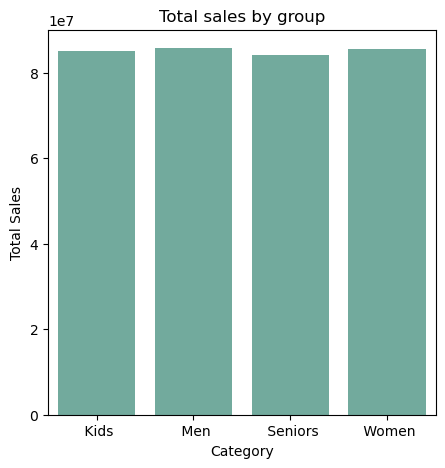

In [46]:
# Bar graph for highest and lowest sales
plt.figure(figsize=(11,5))
plt.subplot(1,2,1)
sns.barplot(x=sales_group.index,y=sales_group.values,color='#69b3a2')
plt.title("Total sales by group")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

<font size=3>Sales are highest in 'Men' group. Sales are least in 'Seniors' group.<font>

<font size=5>3. States which have highest and lowest sales</font>

In [47]:
state_sales = df_sales_analysis.groupby('State')['Sales'].sum()
max_state_sales = state_sales.idxmax()
min_state_sales = state_sales.idxmin()

In [48]:
max_state_sales

' VIC'

In [49]:
min_state_sales

' WA'

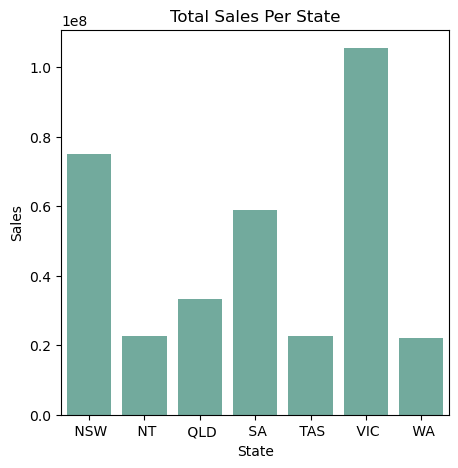

In [50]:
plt.figure(figsize=(11,5))
plt.subplot(1,2,1)
sns.barplot(x=state_sales.index,y=state_sales.values,color='#69b3a2')
plt.title('Total Sales Per State')
plt.xlabel('State')
plt.ylabel('Sales')
plt.show()

<font size=3>VIC has highest sales. WA has lowaet sales<font>

<font size=5>Data Visualization<font>

<font size=4>1. State-wise sales for different groups</font>

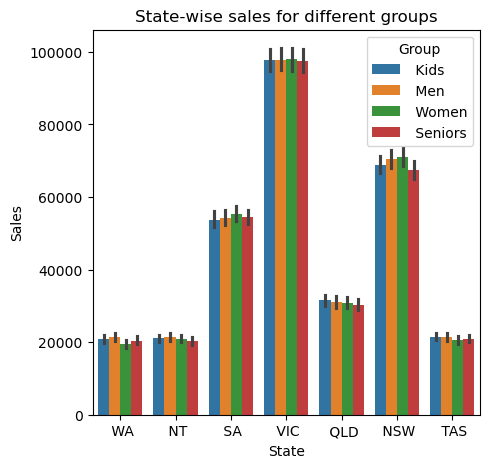

In [51]:
plt.figure(figsize=(11,5))
plt.subplot(1,2,1)
sns.barplot(x='State',y='Sales',hue='Group', data = df_sales_analysis)
plt.title('State-wise sales for different groups')
plt.xlabel('State')
plt.ylabel('Sales')
plt.show()

<font size=4>2. Group-wise sales analysis<font>

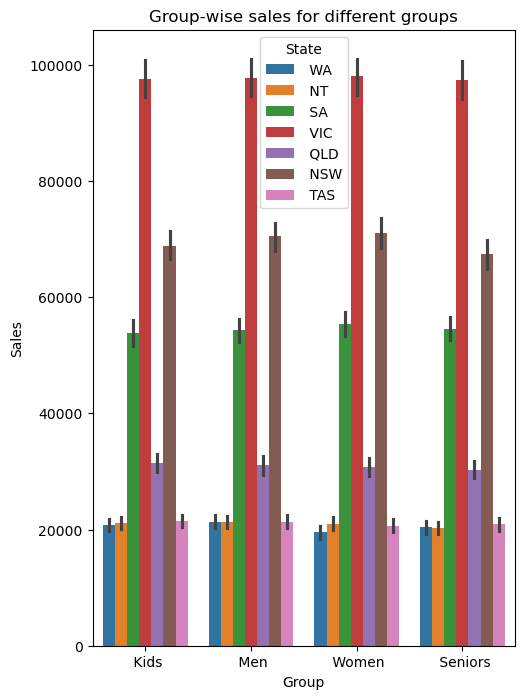

In [52]:
plt.figure(figsize=(12,8))
plt.subplot(1,2,1)
sns.barplot(x='Group',y='Sales',hue='State', data = df_sales_analysis)
plt.title('Group-wise sales for different groups')
plt.xlabel('Group')
plt.ylabel('Sales')
plt.show()

<font size=4>3. Time-of-the-day analysis<font>

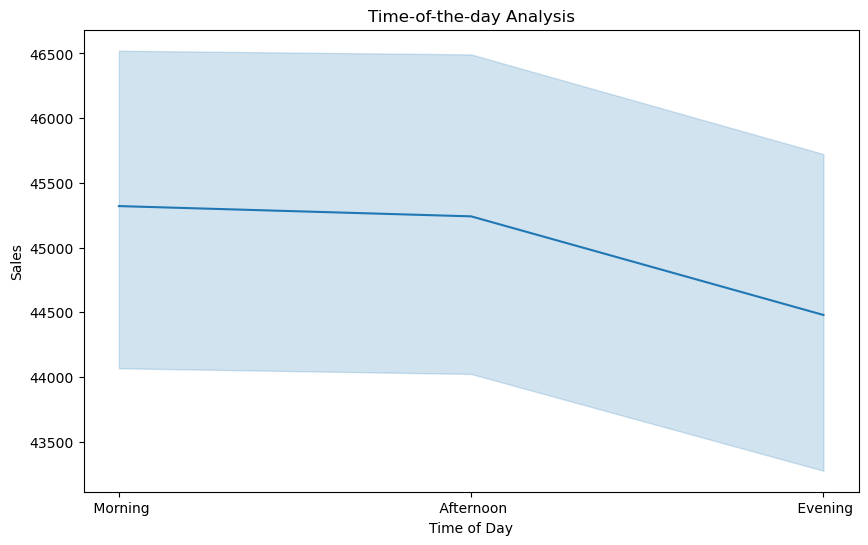

In [53]:
plt.figure(figsize=(10, 6))
sns.lineplot(x='Time', y='Sales', data=df_sales_analysis)
plt.title('Time-of-the-day Analysis')
plt.xlabel('Time of Day')
plt.ylabel('Sales')
plt.show()

<font size=5>Report Generation</font>

<font size=4>Generate weekly, monthly, and quarterly reports<font>

In [54]:
df_sales_analysis.dtypes

Date                 object
Time                 object
State                object
Group                object
Unit                  int64
Sales                 int64
Sales_Normalized    float64
Unit_Normalized     float64
dtype: object

In [55]:
# convert Date column to datetime
df_sales_analysis['Date']=pd.to_datetime(df_sales_analysis['Date'])

In [56]:
# set date column as index
df_sales_analysis.set_index('Date',inplace=True)

In [57]:
# Resample data WEEKLY,MONTHLY AND QUARTERLY
weekly_report = df_sales_analysis.resample('W-Mon').sum()['Sales']
monthly_report = df_sales_analysis.resample('M').sum()['Sales']
quarterly_report = df_sales_analysis.resample('Q').sum()['Sales']

In [58]:
print("Weekly Report:")
weekly_report

Weekly Report:


Date
2020-10-05    18907500
2020-10-12    26935000
2020-10-19    26805000
2020-10-26    26590000
2020-11-02    20797500
2020-11-09    21065000
2020-11-16    21242500
2020-11-23    21187500
2020-11-30    21442500
2020-12-07    30817500
2020-12-14    32060000
2020-12-21    31247500
2020-12-28    32007500
2021-01-04     9197500
Freq: W-MON, Name: Sales, dtype: int64

In [59]:
print("Monthly Report:")
monthly_report

Monthly Report:


Date
2020-10-31    114290000
2020-11-30     90682500
2020-12-31    135330000
Freq: ME, Name: Sales, dtype: int64

In [60]:
print("Qyarterly Report:")
quarterly_report

Qyarterly Report:


Date
2020-12-31    340302500
Freq: QE-DEC, Name: Sales, dtype: int64

<font size = 5> Visualise weekly,monthly and quarterly reports</font>

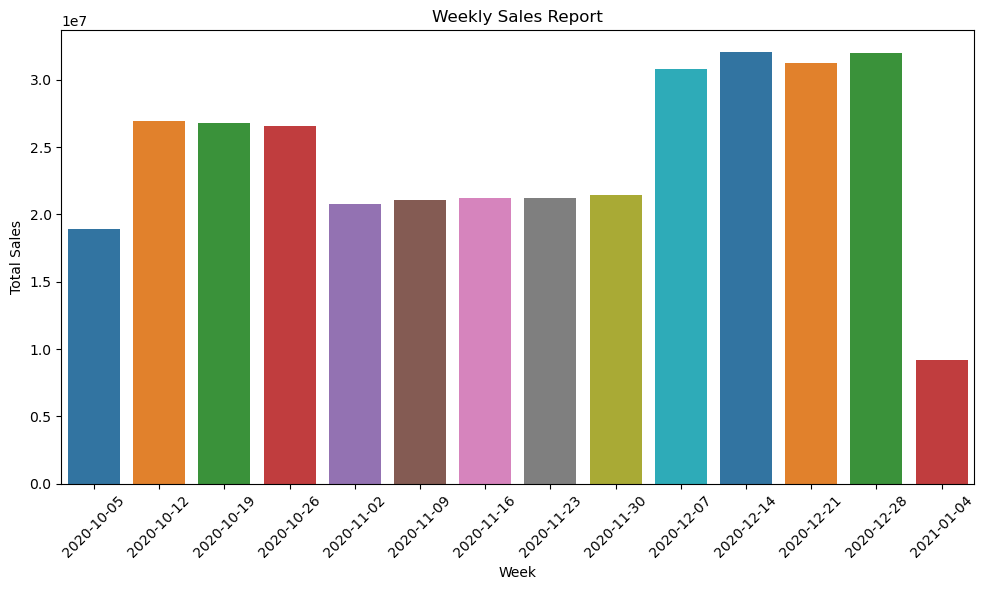

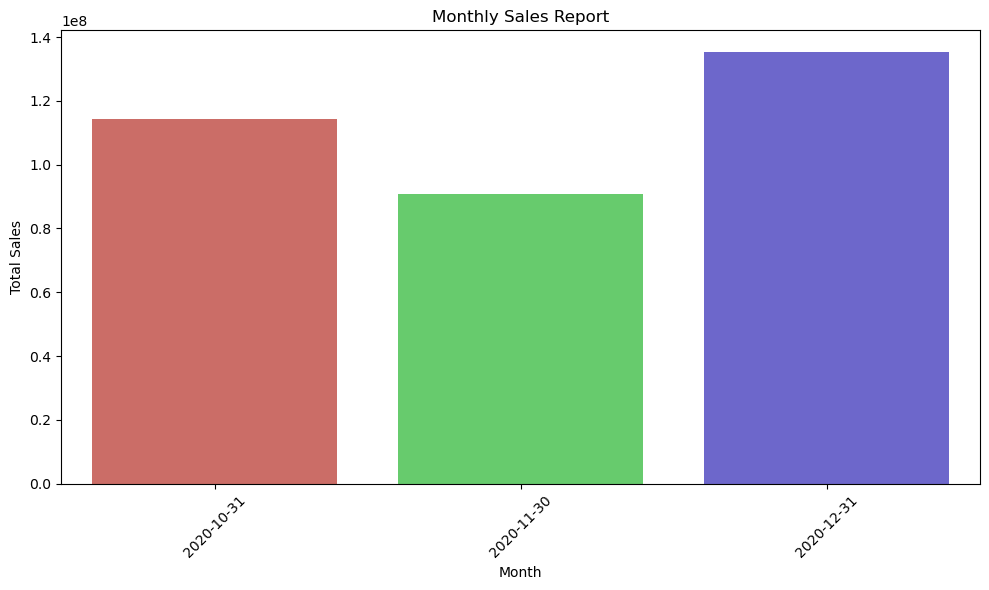

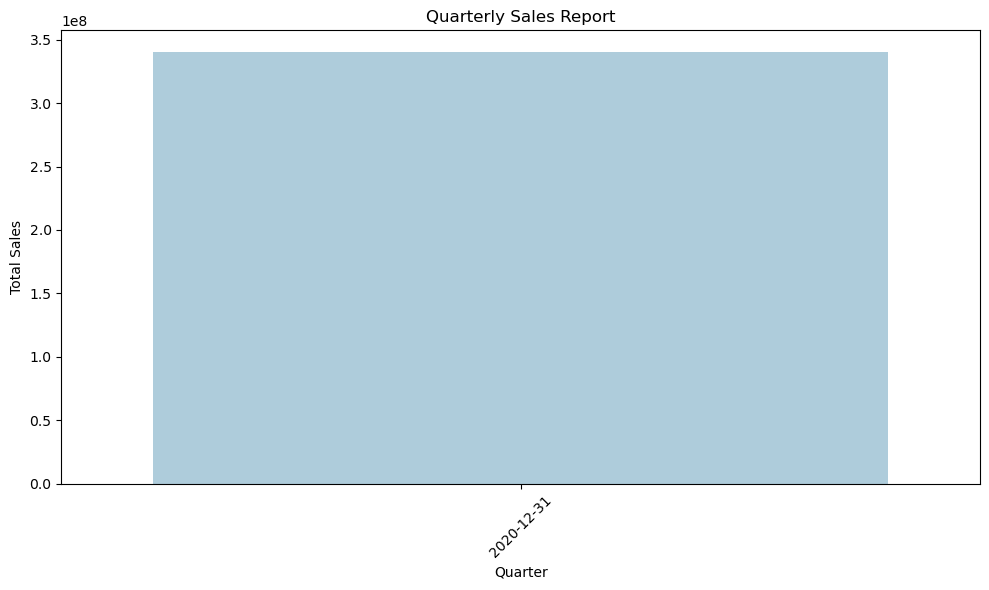

In [61]:
# Plot weekly report with Seaborn
plt.figure(figsize=(10, 6))
sns.barplot(x=weekly_report.index, y=weekly_report.values, palette='tab10')
plt.title('Weekly Sales Report')
plt.xlabel('Week')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot monthly report with Seaborn
plt.figure(figsize=(10, 6))
sns.barplot(x=monthly_report.index, y=monthly_report.values, palette='hls')
plt.title('Monthly Sales Report')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Plot quarterly report with Seaborn
plt.figure(figsize=(10, 6))
sns.barplot(x=quarterly_report.index, y=quarterly_report.values, palette='Paired')
plt.title('Quarterly Sales Report')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

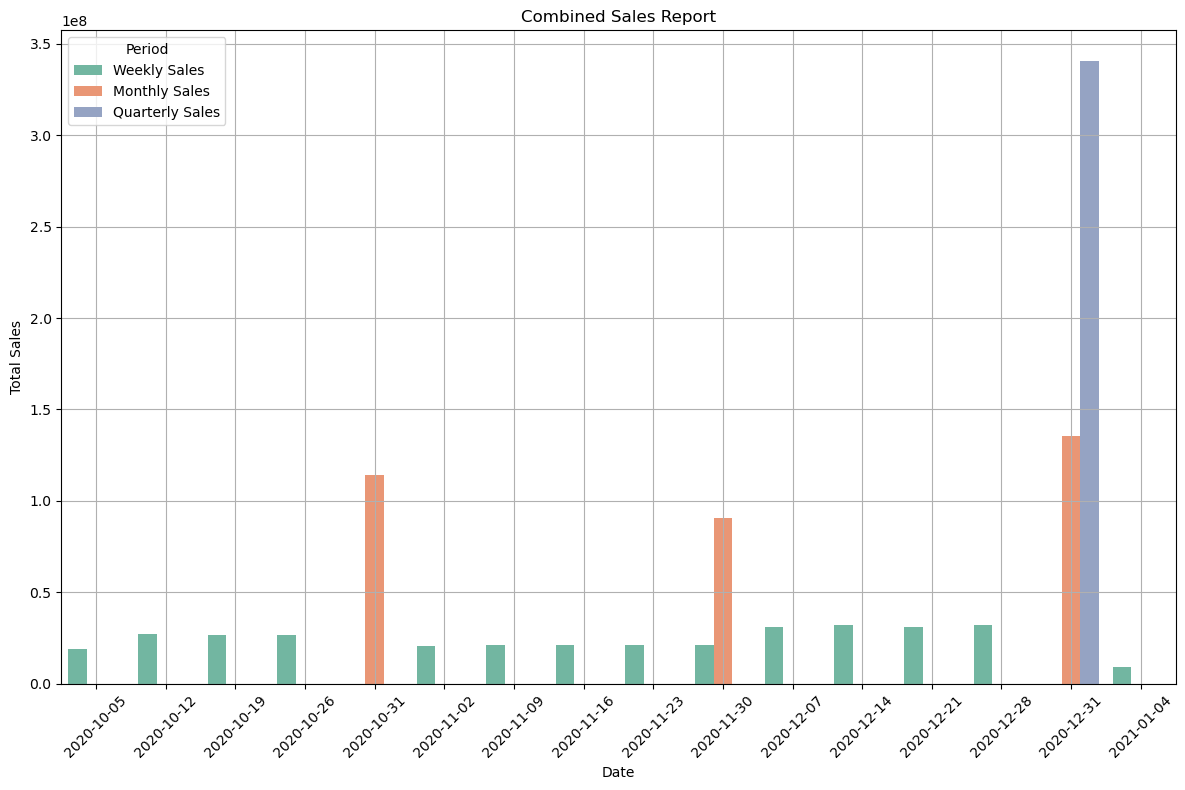

In [62]:
# Combine the reports into a single DataFrame
combined_report = pd.concat([weekly_report, monthly_report, quarterly_report], axis=1)
combined_report.columns = ['Weekly Sales', 'Monthly Sales', 'Quarterly Sales']

# Reset index to convert dates to a column
combined_report.reset_index(inplace=True)

# Melt the DataFrame to have 'Date' as x-axis and 'Sales' as y-axis
melted_report = pd.melt(combined_report, id_vars='Date', var_name='Report Period', value_name='Sales')

# Plot the combined report using Seaborn
plt.figure(figsize=(12, 8))
sns.barplot(data=melted_report, x='Date', y='Sales', hue='Report Period',palette='Set2')
plt.title('Combined Sales Report')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.legend(title='Period', loc='upper left')
plt.tight_layout()
plt.show()